# Bank churn prediction

Exploratory analysis and the modeling story. The reusable code lives in `src/churn/`
(features, model pipelines, training and report scripts); this notebook imports from it.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

from churn.data import load_data, split_xy
from churn.model import MODELS
from churn.train import cross_validate

/Users/muhammadaminesaev/Downloads/new_task/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train, test = load_data()

display(train.head())
display(test.head())

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15702656.0,Nwora,567.0,France,Male,33.0,9.0,0.0,2.0,1.0,0.0,156792.89,0.0
1,1,15647965.0,Yevdokimova,628.0,France,Female,38.0,3.0,0.0,1.0,1.0,1.0,51987.99,1.0
2,2,15798834.0,Ch'iu,635.0,France,Female,29.0,3.0,0.0,2.0,1.0,1.0,113079.19,0.0
3,3,15672056.0,Hsia,681.0,France,Male,28.0,6.0,0.0,2.0,1.0,0.0,14081.64,0.0
4,4,15759537.0,Okwudilichukwu,587.0,France,Female,27.0,5.0,0.0,2.0,1.0,0.0,158958.90,0.0


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,15000,15732563.0,Hs?,707.0,Germany,Male,21.0,4.0,114513.66,2.0,1.0,0.0,176692.87
1,15001,15727041.0,Ma,678.0,Germany,Male,33.0,5.0,142510.50,1.0,0.0,0.0,52820.13
2,15002,15753679.0,K?,636.0,Spain,Male,45.0,9.0,0.00,2.0,1.0,1.0,125062.02
3,15003,15581554.0,H?,697.0,Spain,Male,46.0,8.0,0.00,2.0,1.0,0.0,131647.41
4,15004,15773723.0,Bellucci,553.0,Spain,Male,31.0,2.0,0.00,2.0,1.0,0.0,58814.41


## Exploratory analysis

In [3]:
print("train:", train.shape)
print("test:", test.shape)
print(train.isnull().sum())

train: (15000, 14)
test: (10000, 13)
id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


Exited
0.0    12023
1.0     2977
Name: count, dtype: int64
Exited
0.0    0.801533
1.0    0.198467
Name: proportion, dtype: float64


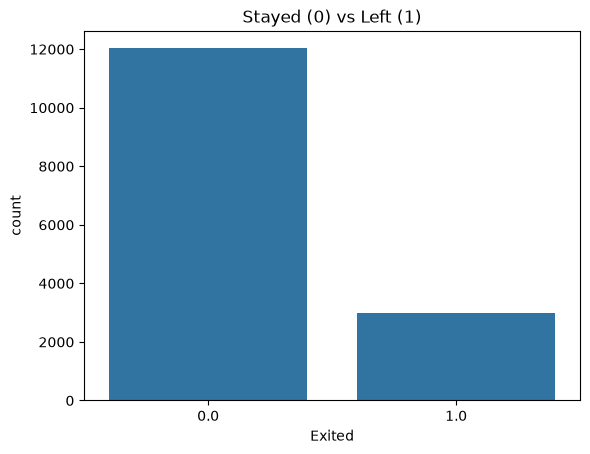

In [4]:
print(train["Exited"].value_counts())
print(train["Exited"].value_counts(normalize=True))

sns.countplot(x="Exited", data=train)
plt.title("Stayed (0) vs Left (1)")
plt.show()

In [5]:
pd.DataFrame({"dtype": train.dtypes, "n_unique": train.nunique()})

,dtype,n_unique
id,int64,15000
CustomerId,float64,6306
Surname,str,758
CreditScore,float64,378
Geography,str,3
Gender,str,2
Age,float64,55
Tenure,float64,11
Balance,float64,3328
NumOfProducts,float64,5


In [6]:
print(train["NumOfProducts"].value_counts().sort_index())
print()
print("Customers with Balance == 0:", (train["Balance"] == 0).mean())

NumOfProducts
1.0    6379
2.0    8406
3.0     194
4.0      20
5.0       1
Name: count, dtype: int64

Customers with Balance == 0: 0.6534666666666666


In [7]:
for col in ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard"]:
    summary = train.groupby(col)["Exited"].agg(["mean", "count"])
    summary.columns = ["churn_rate", "customers"]
    print(summary.round(3))
    print()

           churn_rate  customers
Geography                       
France          0.154       9040
Germany         0.406       2680
Spain           0.152       3280

        churn_rate  customers
Gender                       
Female       0.276       6522
Male         0.139       8478

               churn_rate  customers
NumOfProducts                       
1.0                 0.380       6379
2.0                 0.042       8406
3.0                 0.954        194
4.0                 0.850         20
5.0                 1.000          1

                churn_rate  customers
IsActiveMember                       
0.0                  0.273       7560
1.0                  0.123       7440

           churn_rate  customers
HasCrCard                       
0.0             0.206       3313
1.0             0.196      11687



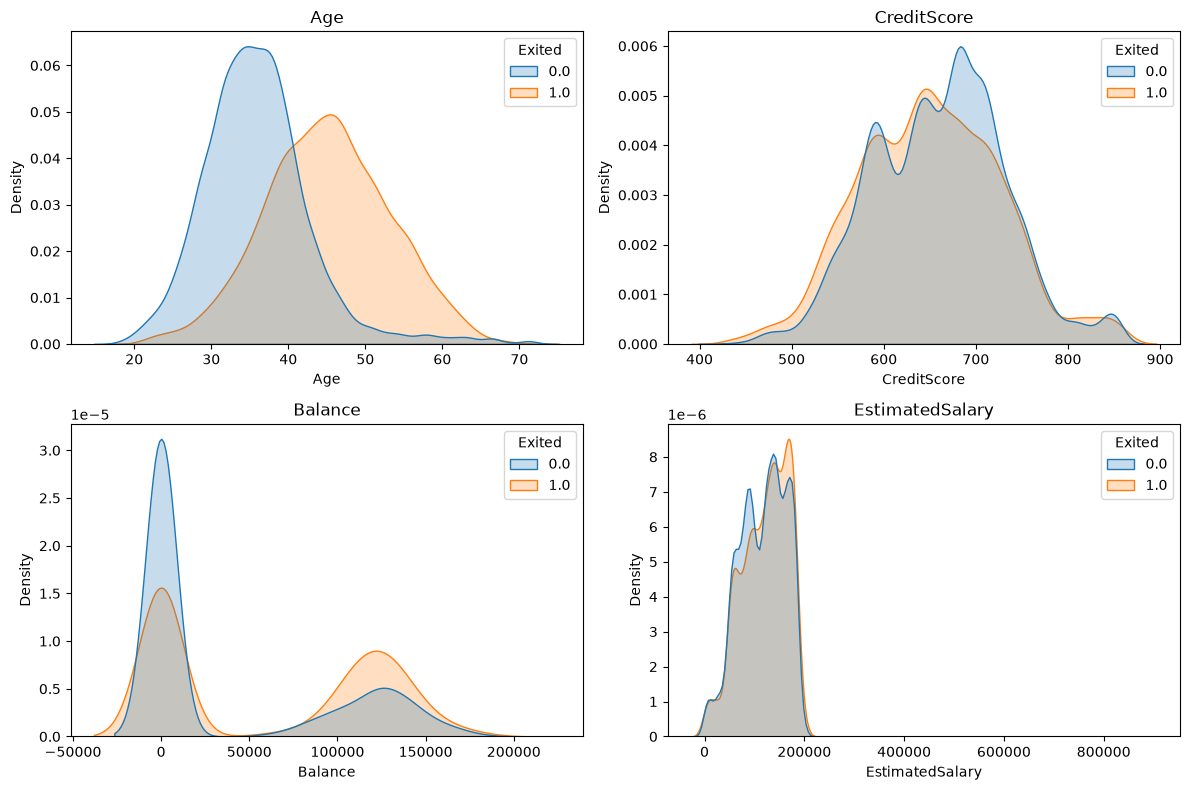

In [8]:
num_cols = ["Age", "CreditScore", "Balance", "EstimatedSalary"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, num_cols, strict=True):
    sns.kdeplot(data=train, x=col, hue="Exited", common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## CustomerId and duplicates
`CustomerId` has far fewer unique values than rows. If it identified real customers, the same person could land in both
training and validation folds and inflate the CV score. Check before trusting the CV.

In [9]:
feature_cols = [c for c in test.columns if c != "id"]

print("Duplicate feature rows in train:", train.duplicated(subset=feature_cols).sum())
print(
    "Test rows identical to a train row:",
    test.merge(train[feature_cols].drop_duplicates(), on=feature_cols).shape[0],
)
print(
    "Test CustomerIds also in train:", round(test["CustomerId"].isin(train["CustomerId"]).mean(), 3)
)
print()
print("Rows per CustomerId:")
print(train["CustomerId"].value_counts().describe().round(2))

Duplicate feature rows in train: 0
Test rows identical to a train row: 0
Test CustomerIds also in train: 0.807

Rows per CustomerId:
count    6306.00
mean        2.38
std         1.93
min         1.00
25%         1.00
50%         2.00
75%         3.00
max        23.00
Name: count, dtype: float64


In [10]:
# If CustomerId were a real person, repeated rows would share Age, Surname and label.
repeated = train[train["CustomerId"].duplicated(keep=False)].groupby("CustomerId")
print("Repeated ids with different Age:    ", round((repeated["Age"].nunique() > 1).mean(), 3))
print("Repeated ids with different Surname:", round((repeated["Surname"].nunique() > 1).mean(), 3))
print("Repeated ids with different Exited: ", round((repeated["Exited"].nunique() > 1).mean(), 3))

Repeated ids with different Age:     0.982
Repeated ids with different Surname: 0.999
Repeated ids with different Exited:  0.492


**Takeaway:** no duplicate rows, and repeated `CustomerId`s mostly have different ages, surnames and labels, so the id is a
synthetic artifact, not a real person. Grouped CV (below) gives the same score as plain stratified CV, so there is no leak
and `StratifiedKFold` is fine.

## Models
Both pipelines (`churn.model`) take the raw columns and do their own feature engineering (`churn.features.add_features`)
and encoding, so encoders are fit on training folds only and train/test always get the same columns.

In [11]:
X, y = split_xy(train)

oof = {}
for name, build in MODELS.items():
    aucs, oof[name], _, _ = cross_validate(build(), X, y, folds=5, seed=42)
    print(f"{name}: AUC {aucs.mean():.4f} ± {aucs.std():.4f}  folds={aucs.round(4)}")

logreg: AUC 0.9275 ± 0.0035  folds=[0.9339 0.9233 0.9267 0.9259 0.9278]


hgb: AUC 0.9301 ± 0.0026  folds=[0.9337 0.9277 0.9304 0.9268 0.9321]


Engineered features (and one-hot `NumOfProducts`) lift logistic regression from 0.883 to about 0.928, close to
gradient boosting. Boosting barely changes, because trees find those splits on their own.

In [12]:
# Sanity check: keep each CustomerId's rows in one fold. Same score => no leak via repeated ids.
group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    MODELS["hgb"](), X, y, cv=group_cv, groups=train["CustomerId"], scoring="roc_auc"
)
print(f"hgb (grouped by CustomerId): AUC {scores.mean():.4f} ± {scores.std():.4f}")

hgb (grouped by CustomerId): AUC 0.9295 ± 0.0048


## Business view
The charts below are produced by `python -m churn.train` followed by `python -m churn.report`, from out-of-fold
predictions (each customer scored by a model that never saw them).

If the bank contacts customers in order of predicted risk, how many future churners does it reach?

 contacted  churners_caught  precision  lift
       0.1            0.451      0.895  4.51
       0.2            0.733      0.727  3.66
       0.3            0.870      0.576  2.90


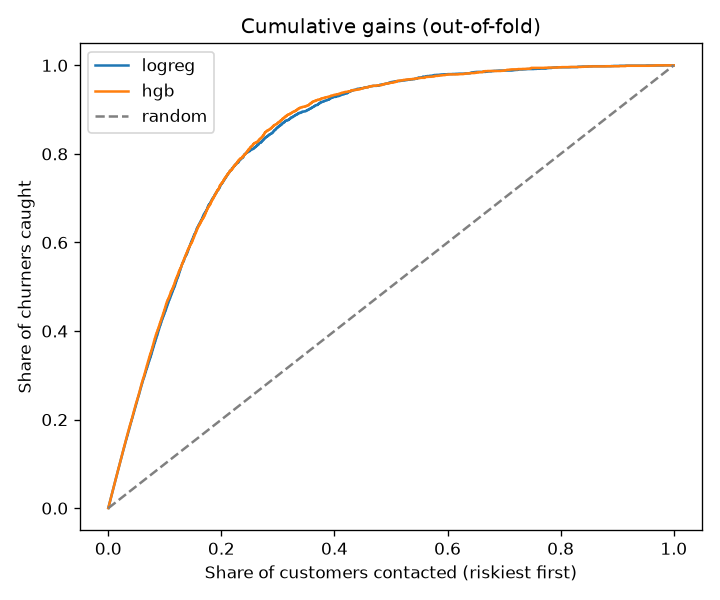

In [13]:
print(pd.read_json("../reports/gains.json").to_string(index=False))
display(Image("../reports/gains.png", width=450))

Contacting the riskiest 20% of customers reaches about 73% of churners, 3.7x better than contacting at random.
Where to set the cutoff is a business decision: a real bank would plug in its own cost per contact and value of a
retained customer to choose the share.

## Why customers churn
Permutation importance and partial dependence, computed on a held-out CV fold.

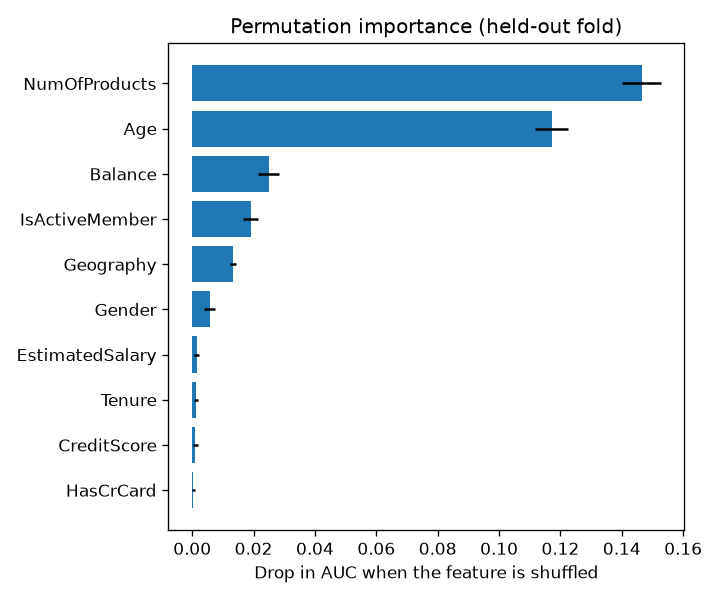

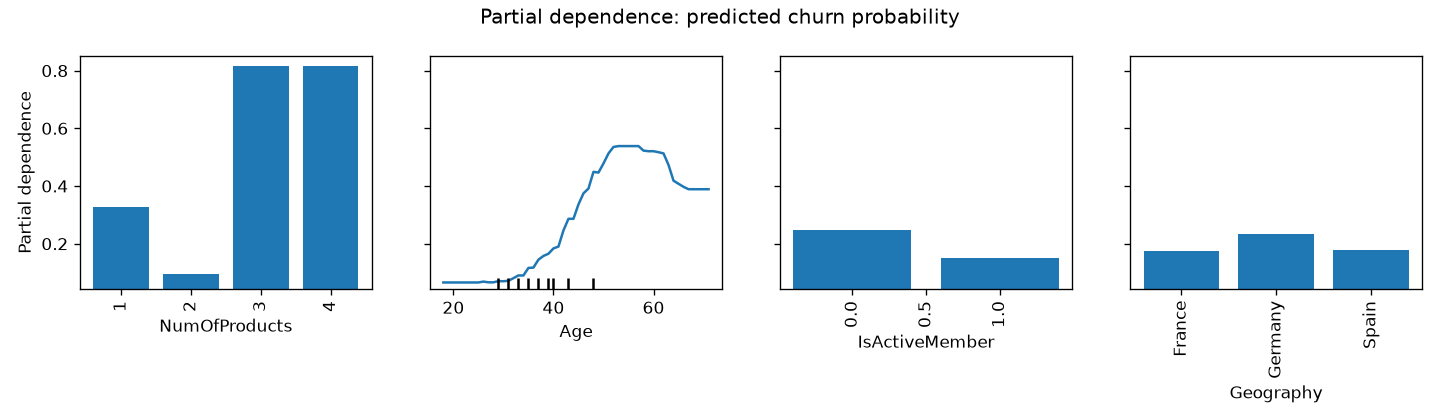

In [14]:
display(Image("../reports/importance.png", width=450))
display(Image("../reports/partial_dependence.png"))

The model confirms the EDA:
- **NumOfProducts** matters most and is U-shaped: 2 products is by far the safest, 3+ almost always churn.
- **Age** is next: risk climbs from the mid-30s and peaks around 50-60.
- **Inactive members** churn more. **Germany**'s raw 41% churn rate shrinks once age, balance and products are
  accounted for, so much of the "Germany effect" comes from who the German customers are.
- Credit score, tenure, salary and card ownership add almost nothing.